## FUTSAL GOAL PREDICTION:

In [52]:
#REQS
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
import joblib
import os

In [53]:
#Load Data
df= pd.read_csv("../data/futsal_shots.csv")
print(df.head(5))
print(df.columns.tolist())
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["goal"].value_counts())
os.makedirs("outputs/plots", exist_ok=True)
os.makedirs("outputs/reports",exist_ok=True)
os.makedirs("models", exist_ok=True)

   shot_distance  shot_angle  defensive_pressure  goalkeeper_distance  goal
0           11.9        58.5                 2.9                 10.7     1
1            7.4        42.7                 3.2                 10.8     1
2           13.1        50.2                 0.4                  6.5     0
3           10.9        66.2                 2.1                  4.1     0
4            2.8        55.8                 0.2                  9.4     1
['shot_distance', 'shot_angle', 'defensive_pressure', 'goalkeeper_distance', 'goal']
(60, 5)
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   shot_distance        60 non-null     float64
 1   shot_angle           60 non-null     float64
 2   defensive_pressure   60 non-null     float64
 3   goalkeeper_distance  60 non-null     float64
 4   goal                 60 non-null     int64  
dtypes: fl

In [54]:
# Data Validation:
X_FEATURES=["shot_distance", "shot_angle", "defensive_pressure", "goalkeeper_distance"]
y_TARGET="goal"
required_colums=X_FEATURES+[y_TARGET]
missing_columns= set(required_colums) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing Columns: {missing_columns}")
df=df[required_colums].copy()

if not set(df[y_TARGET].dropna().unique()).issubset({0,1}):
    raise ValueError("Target must contain only 0 and 1")

for column in required_colums:
    df[column]=pd.to_numeric(df[column], errors="coerce")

df=df.dropna(subset=[y_TARGET])
print(df.isnull().sum())
print(f"Final Dataset shape: {df.shape}")

shot_distance          0
shot_angle             0
defensive_pressure     0
goalkeeper_distance    0
goal                   0
dtype: int64
Final Dataset shape: (60, 5)


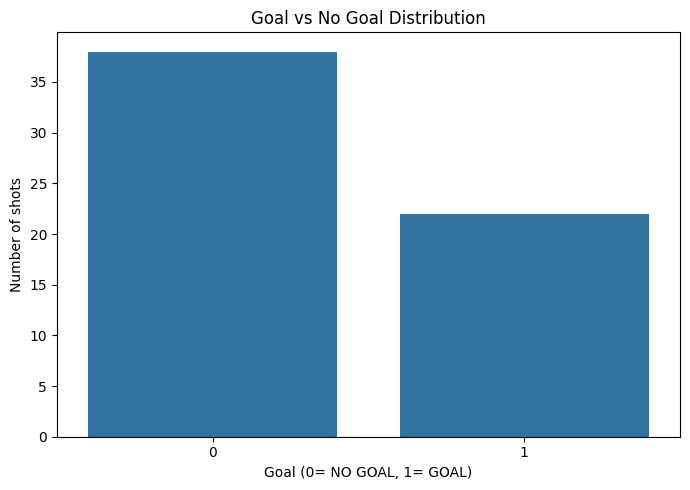

In [55]:
#Goal Distribution
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="goal")
plt.title("Goal vs No Goal Distribution")
plt.xlabel("Goal (0= NO GOAL, 1= GOAL)")
plt.ylabel("Number of shots")
plt.tight_layout()
plt.savefig("outputs/plots/goal_dist.png",dpi=150)

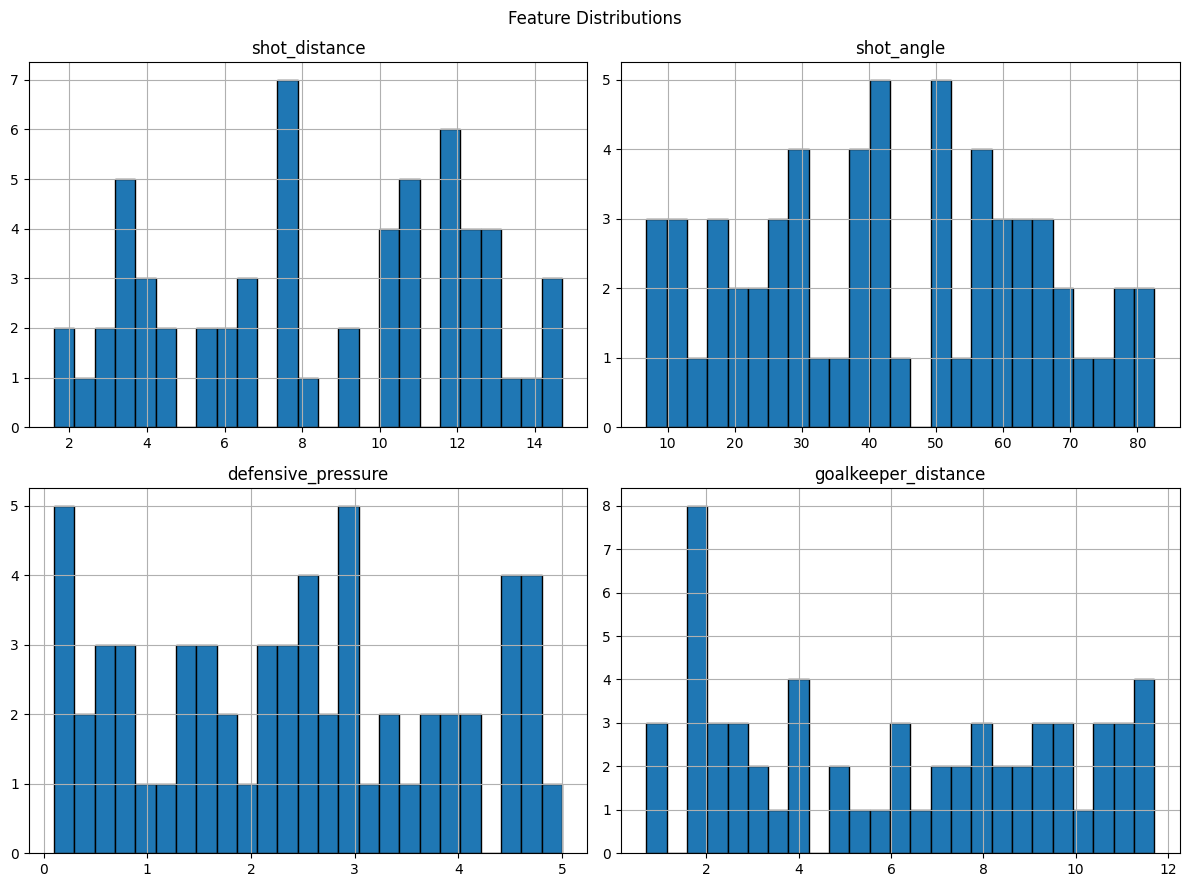

In [56]:
# Feature Distributions
df[X_FEATURES].hist(figsize=(12,9), bins=25, edgecolor="black")
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.savefig("outputs/plots/feature_dist.png", dpi=150)

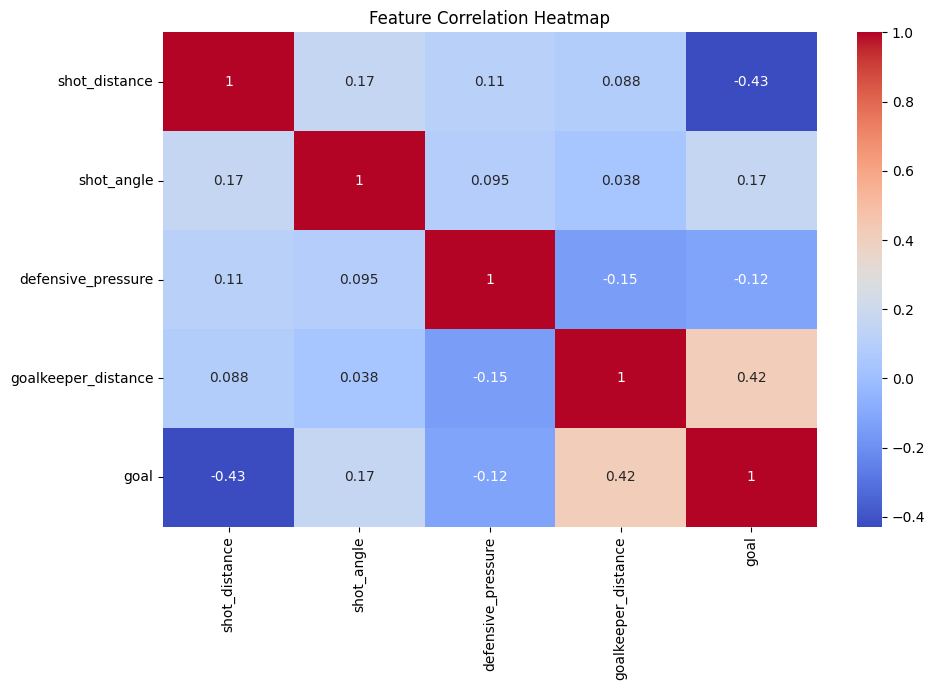

In [57]:
#Feature Relationships
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/plots/correlation_heatmap.png", dpi=150)


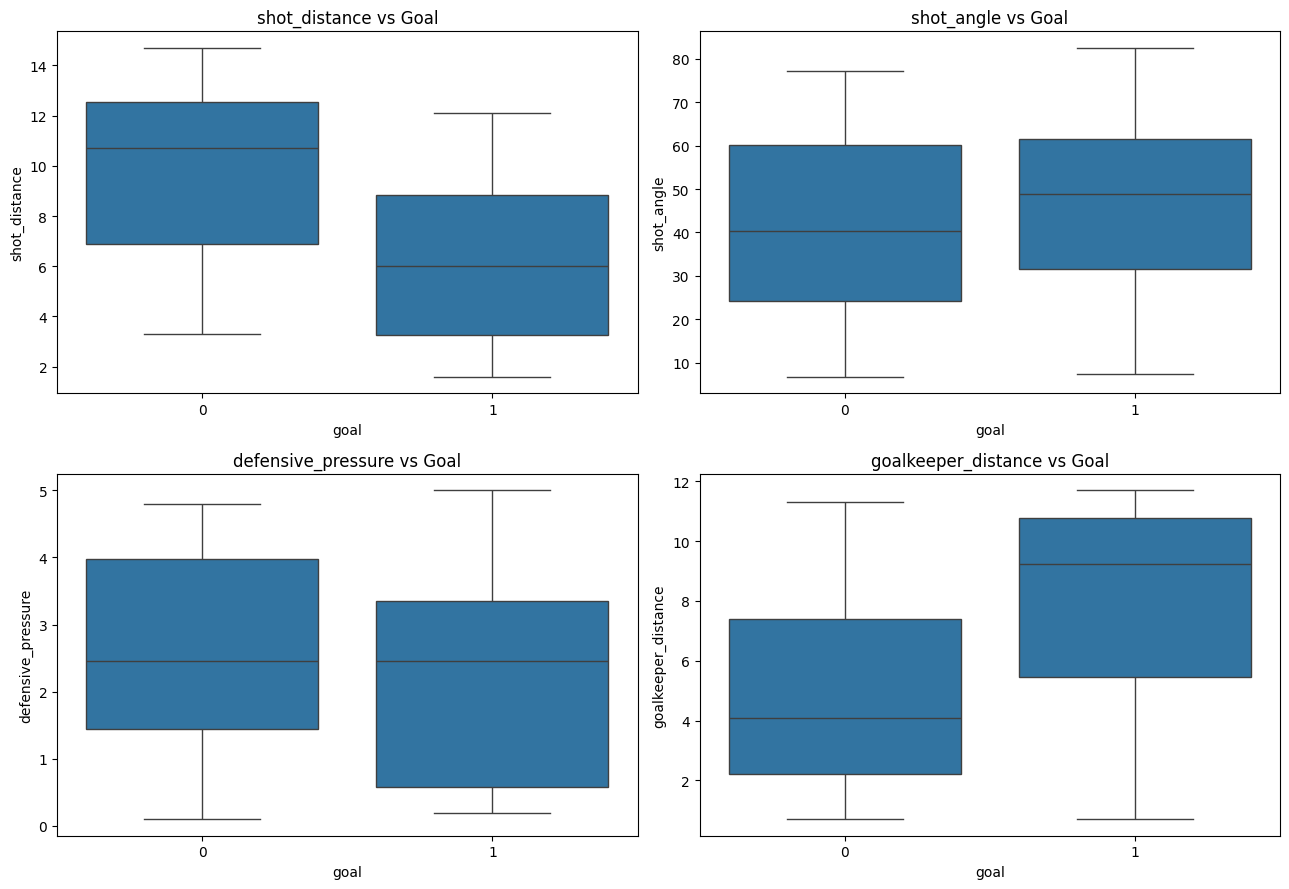

In [58]:
# Feature Comparision with goal outcome
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for feature, ax in zip(X_FEATURES, axes.flatten()):
    sns.boxplot(
        data=df,
        x="goal",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} vs Goal")

plt.tight_layout()

plt.savefig("outputs/plots/feature_vs_goal.png",dpi=300)

plt.show()

In [59]:
X=df[X_FEATURES]
y=df[y_TARGET]

#Train Test Split
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(f"Training Shape: {X_train.shape}, Testing Shape:{X_test.shape}")
print(f"Training Target Dist: {y_train.value_counts(normalize=True)}, \n Testing Target Dist: {y_test.value_counts(normalize=True)}")

Training Shape: (48, 4), Testing Shape:(12, 4)
Training Target Dist: goal
0    0.625
1    0.375
Name: proportion, dtype: float64, 
 Testing Target Dist: goal
0    0.666667
1    0.333333
Name: proportion, dtype: float64


In [60]:
# Handle missig value
from sklearn.impute import SimpleImputer
def create_pipeline(model, scale=False):
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

Train the seven machine learning models

In [61]:
#Define Models
logistic_model= create_pipeline(
    LogisticRegression(max_iter=2000, random_state=42),
    scale=True
)
decision_model= create_pipeline(
    DecisionTreeClassifier(random_state=42)
)
random_model= create_pipeline(
    RandomForestClassifier(random_state=42, n_jobs=-1)
)
voting_model= create_pipeline(
    VotingClassifier(
        estimators=[
            ("lr", LogisticRegression(max_iter=2000)),
            ("dt", DecisionTreeClassifier(random_state=42)),
            ("rf", RandomForestClassifier(
                n_estimators=100, random_state=42, n_jobs=1
            ))
        ],
        voting="soft"
    )
)
adaboost_model=create_pipeline(
    AdaBoostClassifier(random_state=42)
)
gradient_model=create_pipeline(
    GradientBoostingClassifier(random_state=42)
)
xgb_model=create_pipeline(
    XGBClassifier(
        random_state=42,
        eval_metrics="logloss",
        n_obs=1
    )
)

In [62]:
#Model Dictionary
models={
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_model,
    "Random Forest": random_model,
    "Voting Classifier": voting_model,
    "AdaBoost": adaboost_model,
    "Gradient Boosting": gradient_model,
    "XGBoost": xgb_model
}

In [63]:
#Hyperparameters for models
param_grids={
    "Logistic Regression":{
        "model__C":[0.01, 0.1, 1, 10],
        "model__class_weight":[None, "balanced"]
    },
    "Decision Tree":{
        "model__max_depth":[3,5,10,None],
        "model__min_samples_split":[2,5,10],
        "model__min_samples_leaf":[1,2,5],
        "model__class_weight":[None, "balanced"]
    },
    "Random Forest":{
        "model__n_estimators":[100,200],
        "model__max_depth":[None, 5, 10],
        "model__min_samples_leaf":[1,2,5],
        "model__class_weight":[None, "balanced"]
    },
    "Voting Classifier":{
        "model__weights":[
            [1,1,1],
            [2,1,1],
            [1,1,2],
            [1,2,2]
        ]
    },
    "AdaBoost":{
        "model__n_estimators":[50, 100, 200],
        "model__learning_rate":[0.01, 0.1, 1.0]
    },
    "Gradient Boosting":{
        "model__n_estimators":[50,100,200],
        "model__learning_rate":[0.01, 0.05, 0.1],
        "model__max_depth":[1,2,3]
    },
    "XGBoost":{
        "model__n_estimators":[100, 200],
        "model__max_depth":[2,3,5],
        "model__learning_rate":[0.01, 0.05, 0.1],
        "model__subsample":[0.8, 1.0]
    }
}

In [64]:
#Cross-validation
cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [65]:
#Tune and Train all models
best_models={}
cv_results={}

for name, model in models.items():
    print(f"Training: {name}")
    search=GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )
    search.fit(X_train, y_train)
    best_models[name]=search.best_estimator_
    cv_results[name]={
        "Best CV Average Precision":search.best_score_,
        "Best Parameters": search.best_params_
    }
    print(f"Best CV AP: {search.best_score_}")
    print(f"Best Parameters: {search.best_params_}")

Training: Logistic Regression
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV AP: 0.8935714285714285
Best Parameters: {'model__C': 10, 'model__class_weight': None}
Training: Decision Tree
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best CV AP: 0.5999206349206349
Best Parameters: {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}
Training: Random Forest
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best CV AP: 0.7698809523809522
Best Parameters: {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Training: Voting Classifier
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best CV AP: 0.7757539682539681
Best Parameters: {'model__weights': [2, 1, 1]}
Training: AdaBoost
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best CV AP: 0.7057539682539682
Best Parameters: {'model__learning_rate': 1.

c:\Users\anamo\OneDrive\Desktop\pythonDownload\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:50:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "eval_metrics", "n_obs" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [66]:
#View cross Validation Results
cv_results_df=pd.DataFrame(cv_results).T
display(cv_results_df)

,Best CV Average Precision,Best Parameters
Logistic Regression,0.893571,"{'model__C': 10, 'model__class_weight': None}"
Decision Tree,0.599921,"{'model__class_weight': None, 'model__max_dept..."
Random Forest,0.769881,"{'model__class_weight': None, 'model__max_dept..."
Voting Classifier,0.775754,"{'model__weights': [2, 1, 1]}"
AdaBoost,0.705754,"{'model__learning_rate': 1.0, 'model__n_estima..."
Gradient Boosting,0.710754,"{'model__learning_rate': 0.1, 'model__max_dept..."
XGBoost,0.764087,"{'model__learning_rate': 0.05, 'model__max_dep..."


In [67]:
#Evaluation:
results=[]
for name, model in best_models.items():
    y_pred=model.predict(X_test)
    y_proba=model.predict_proba(X_test)[:,1]
    metrics={
        "Model":name,
        "Accuracy":accuracy_score(y_test, y_pred),
        "Precision":precision_score(y_test, y_test, zero_division=0),
        "Recall":recall_score(y_test, y_pred, zero_division=0),
        "F1-Score":f1_score(y_test, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_test),
        "Average Precision": average_precision_score(y_test, y_proba)
    }
    results.append(metrics)
comparision_df=pd.DataFrame(results)
comparision_df=comparision_df.sort_values(by="Average Precision", ascending=False).reset_index(drop=True)
display(comparision_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,Balanced Accuracy,Average Precision
0,Random Forest,0.8333,1.0,0.50,0.6667,1.0,0.8929
1,Logistic Regression,0.8333,1.0,0.50,0.6667,1.0,0.8304
2,Voting Classifier,0.8333,1.0,0.50,0.6667,1.0,0.8304
3,Gradient Boosting,0.7500,1.0,0.50,0.5714,1.0,0.7986
4,AdaBoost,0.7500,1.0,0.50,0.5714,1.0,0.7750
5,Decision Tree,0.8333,1.0,0.75,0.7500,1.0,0.7708
6,XGBoost,0.7500,1.0,0.50,0.5714,1.0,0.6667


In [68]:
#Save the Comparision Table
comparision_df.to_csv("outputs/reports/model_comparision.csv", index=False)
print("Comparision Table Saved!")

Comparision Table Saved!


Visualize Model Performance

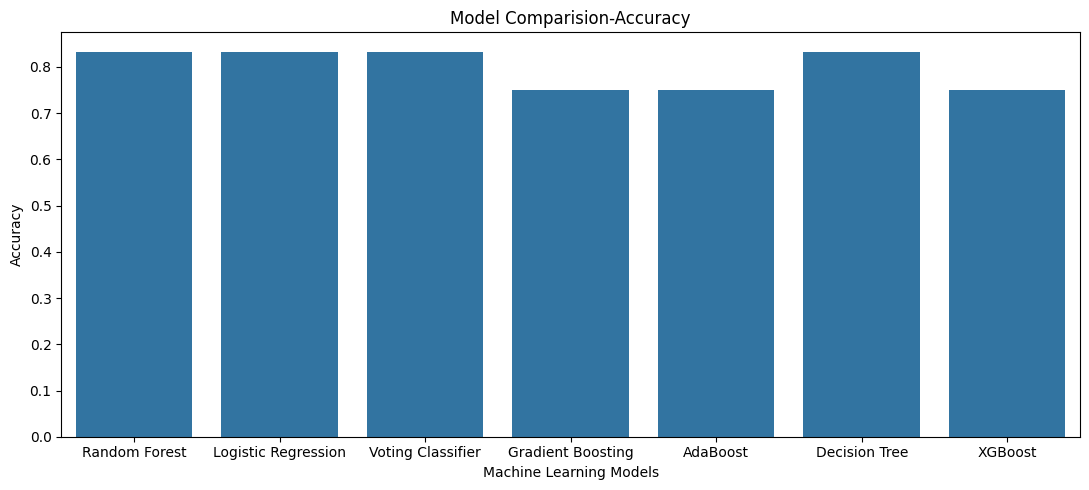

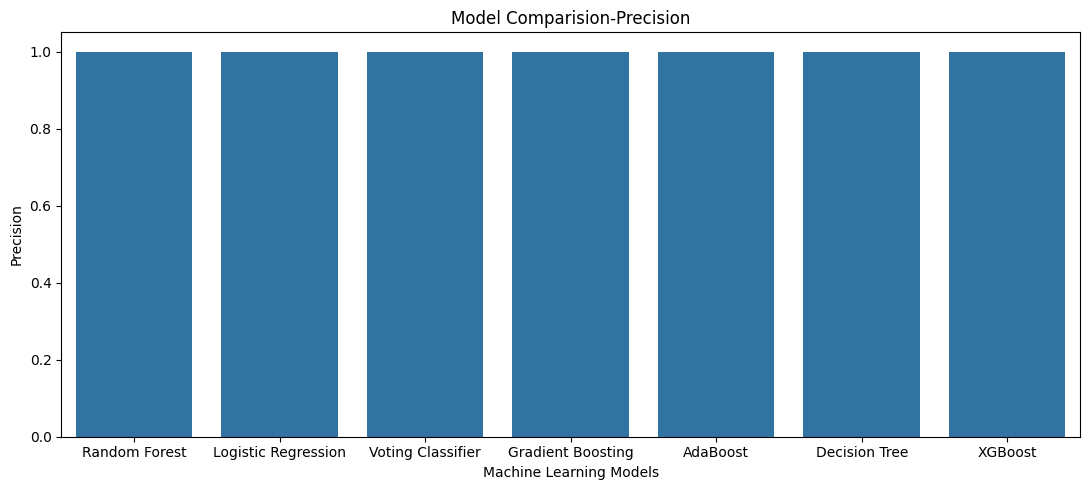

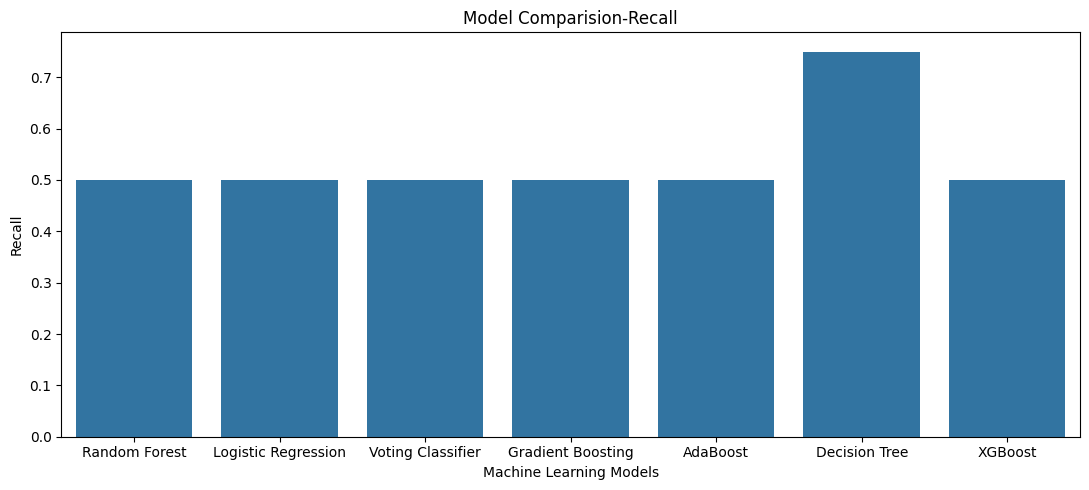

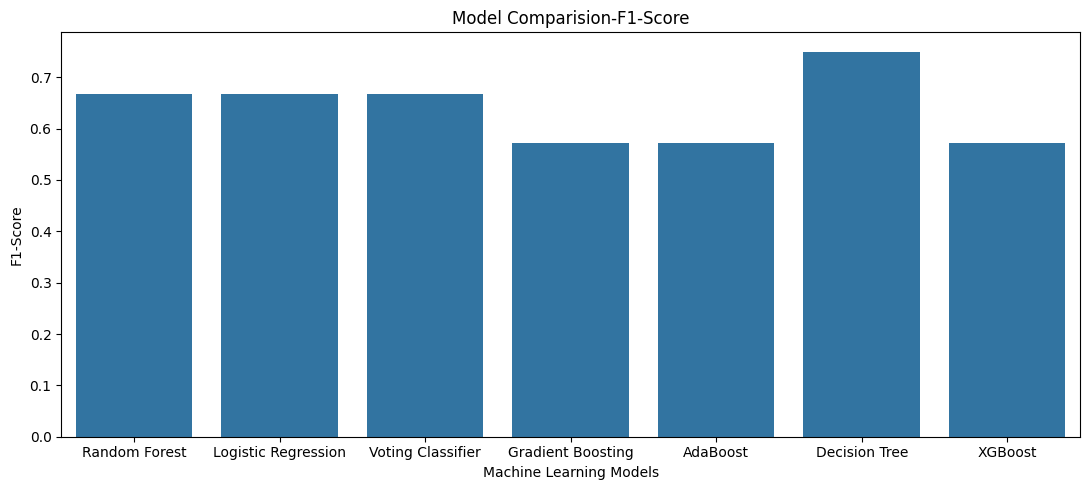

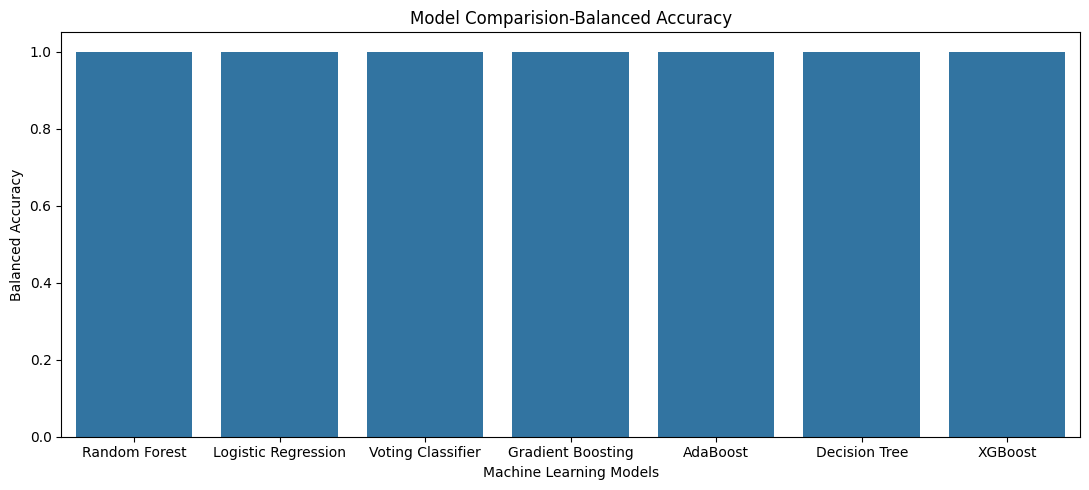

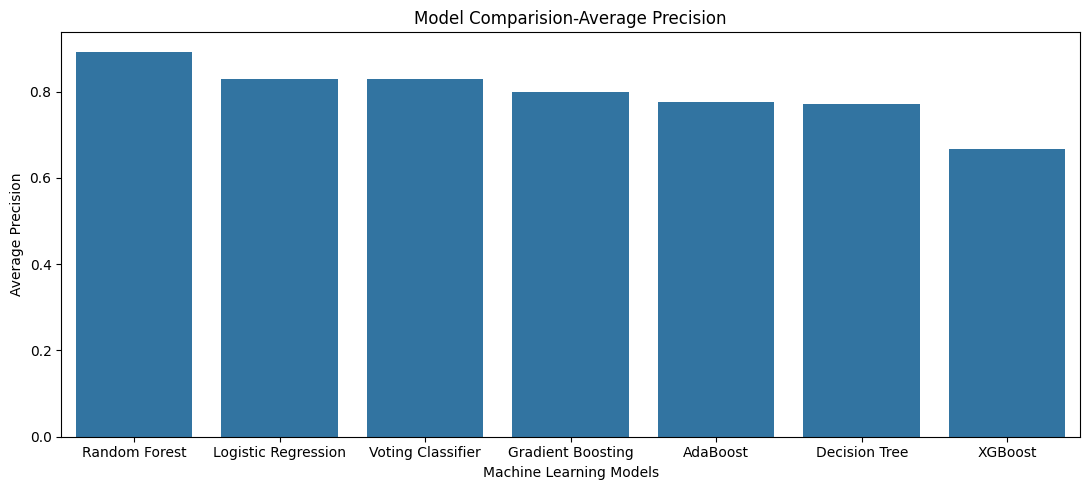

In [69]:
#Compare all metrics
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Balanced Accuracy",
    "Average Precision"
]
for metric in metrics:
    plt.figure(figsize=(11, 5))
    sns.barplot(
        data=comparision_df,
        x="Model",
        y=metric
    )
    plt.title(f"Model Comparision-{metric}")
    plt.xlabel("Machine Learning Models")
    plt.tight_layout()

    plt.savefig("outputs/plots/"f"{metric.lower().replace('','_')}.png", dpi=300)

In [70]:
#Best Model
best_model_name=comparision_df.iloc[0]["Model"]
print("Best Model", best_model_name)
print("Best Average Precision: ", comparision_df.iloc[0]["Average Precision"])
best_model=best_models[best_model_name]

Best Model Random Forest
Best Average Precision:  0.8928571428571428


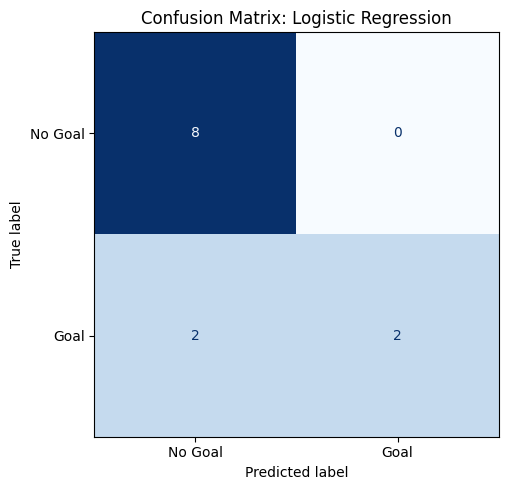

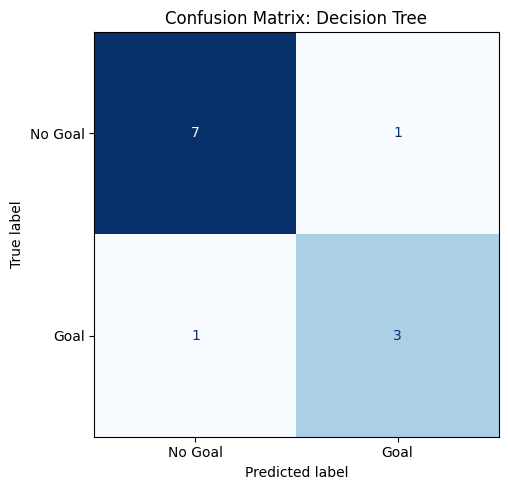

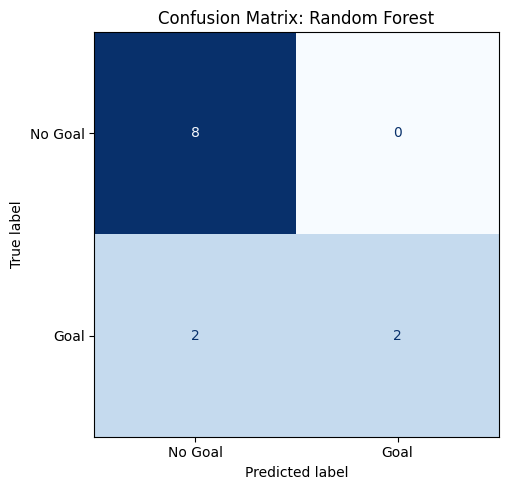

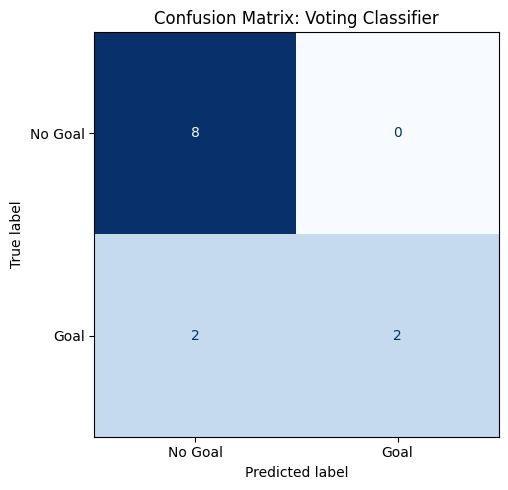

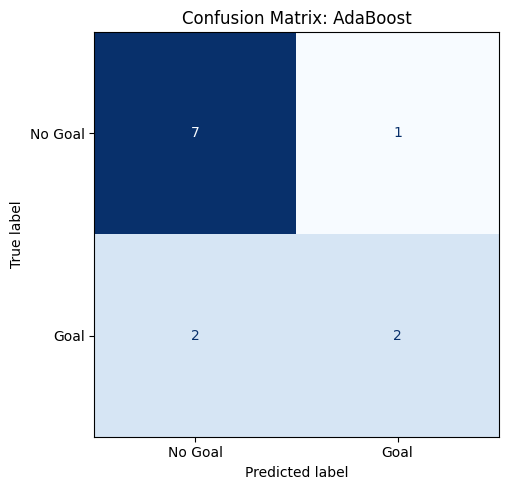

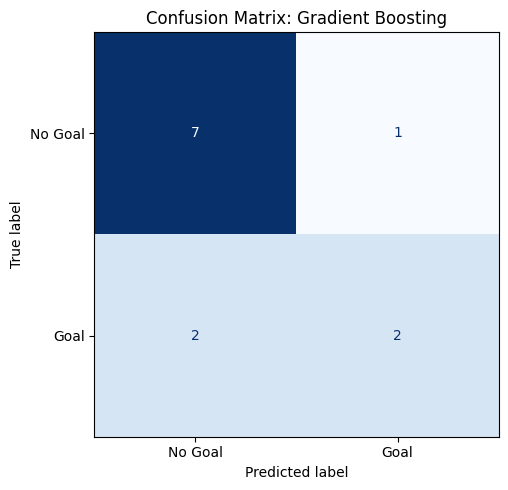

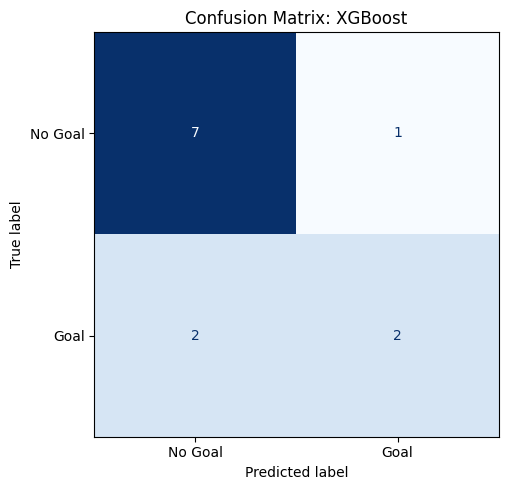

In [71]:
#Confusion Matrix
for name, model in best_models.items():
    y_pred=model.predict(X_test)
    cm= confusion_matrix(
        y_test, y_pred, labels=[0,1]
    )
    display_cm= ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Goal", "Goal"]
    )

    fig, ax= plt.subplots(figsize=(6,5))
    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )
    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    plt.savefig("outputs/plots/"f"{name.lower().replace(' ', '_')}.png", dpi=300)

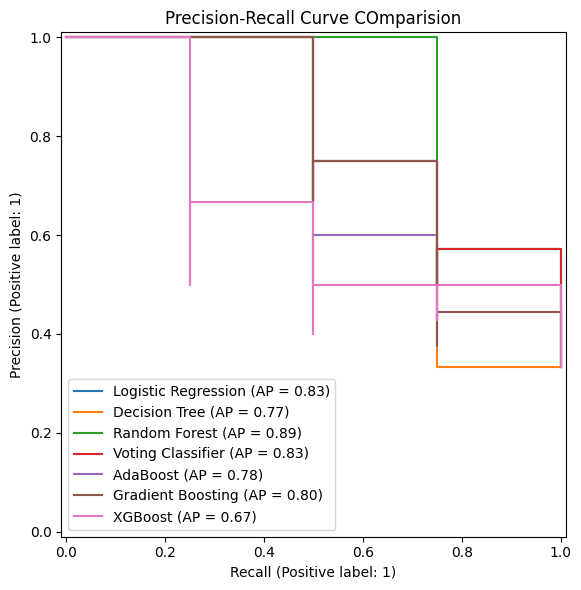

In [72]:
#Precision_Recall Curve
plt.figure(figsize=(9,6))
for name, model in best_models.items():
    y_proba=model.predict_proba(X_test)[:,1]
    PrecisionRecallDisplay.from_predictions(y_test, y_proba, name=name, ax=plt.gca())
plt.title("Precision-Recall Curve COmparision")
plt.tight_layout()
plt.savefig("outputs/plots/precision_recall_comparision.png")

In [73]:
#Detailed Evaluations:
y_pred_best=best_model.predict(X_test)
y_proba_best= best_model.predict_proba(X_test)[:,1]
print("Best Model:", best_model_name)
print("Classification Report : ", classification_report(y_test, y_pred_best, target_names=["No Goal", "Goal"]))

Best Model: Random Forest
Classification Report :                precision    recall  f1-score   support

     No Goal       0.80      1.00      0.89         8
        Goal       1.00      0.50      0.67         4

    accuracy                           0.83        12
   macro avg       0.90      0.75      0.78        12
weighted avg       0.87      0.83      0.81        12



In [74]:
#Predictio Probabilities
prediction_results=X_test.copy()
prediction_results["Actual Goal"]=y_test.values
prediction_results["Predicted Goal"]= y_pred_best
prediction_results["Goal Probabilities"]= y_proba_best
prediction_results["Prediction Result"]=np.where(
    prediction_results["Actual Goal"]==prediction_results["Predicted Goal"],
    "Correct", "Incorrect"
)
display(prediction_results.head(5))

,shot_distance,shot_angle,defensive_pressure,goalkeeper_distance,Actual Goal,Predicted Goal,Goal Probabilities,Prediction Result
29,10.7,45.1,0.1,6.3,0,0,0.245833,Correct
35,4.1,55.4,3.4,9.0,1,1,0.625806,Correct
37,7.9,12.0,3.3,1.9,0,0,0.134048,Correct
11,14.0,37.7,4.6,3.3,0,0,0.013250,Correct
59,3.0,55.2,3.7,1.8,1,0,0.455312,Incorrect


In [75]:
#Experiment with classification threshold
thresholds=[0.3, 0.4, 0.5, 0.6, 0.7]
threshold_results=[]
for threshold in thresholds:
    predictions=(y_proba_best>=threshold).astype(int)
    threshold_results.append({
        "Threshold":threshold,
        "Precision":precision_score(y_test, predictions, zero_division=0),
        "Recall":recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_df=pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.3,0.60,0.75,0.6667
1,0.4,0.75,0.75,0.7500
2,0.5,1.00,0.50,0.6667
3,0.6,1.00,0.25,0.4000
4,0.7,0.00,0.00,0.0000


Decision Tree


,Feature,Importance
3,goalkeeper_distance,0.353107
0,shot_distance,0.301609
1,shot_angle,0.249945
2,defensive_pressure,0.095339


Random Forest


,Feature,Importance
3,goalkeeper_distance,0.420577
0,shot_distance,0.235570
1,shot_angle,0.173815
2,defensive_pressure,0.170038


AdaBoost


,Feature,Importance
0,shot_distance,0.386010
3,goalkeeper_distance,0.341749
1,shot_angle,0.209761
2,defensive_pressure,0.062480


Gradient Boosting


,Feature,Importance
3,goalkeeper_distance,0.474997
0,shot_distance,0.279293
1,shot_angle,0.197615
2,defensive_pressure,0.048095


XGBoost


,Feature,Importance
3,goalkeeper_distance,0.394081
0,shot_distance,0.230796
1,shot_angle,0.192881
2,defensive_pressure,0.182242


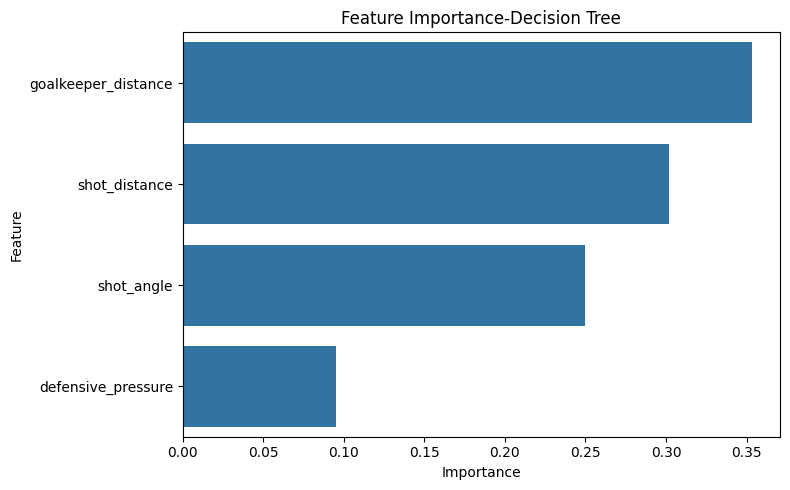

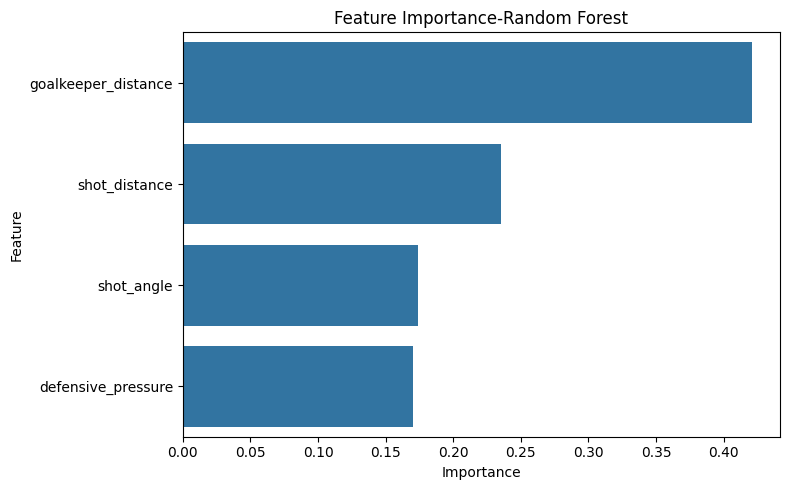

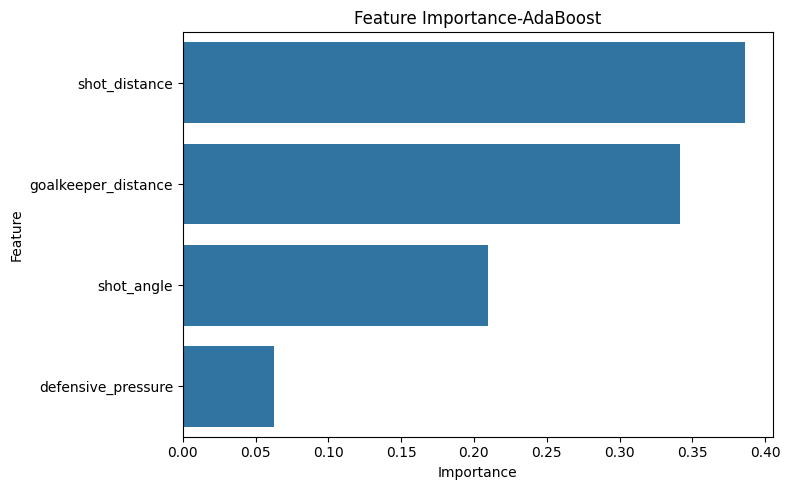

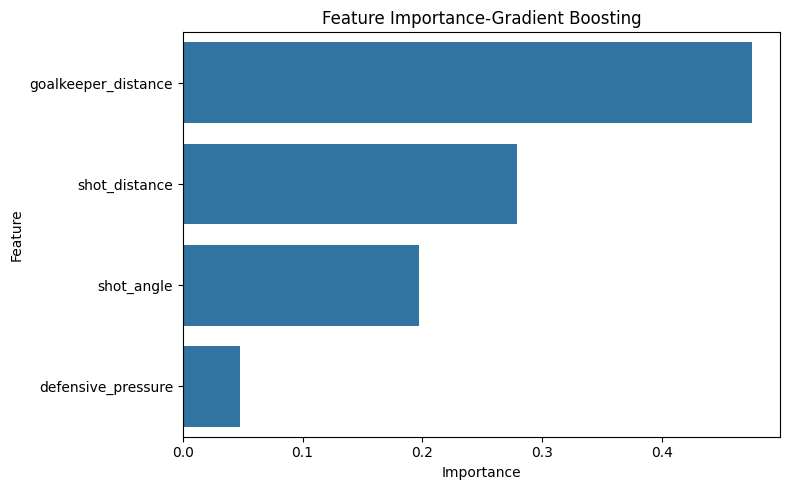

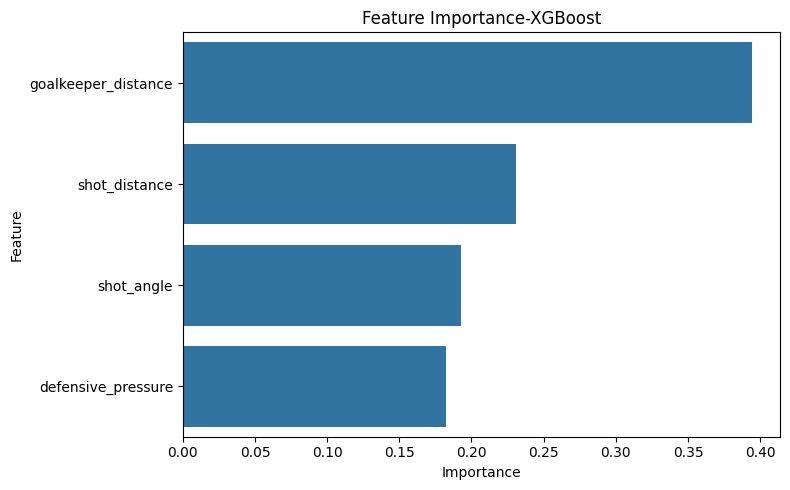

In [76]:
#Those Features which influnce our predictions.
tree_models=[
    "Decision Tree",
    "Random Forest",
    "AdaBoost",
    "Gradient Boosting",
    "XGBoost"
] 
for name in tree_models:
    model=best_models[name]
    classifier=model.named_steps["model"]
    importance= classifier.feature_importances_
    importance_df=pd.DataFrame({
        "Feature": X_FEATURES,
        "Importance": importance
    }).sort_values(by="Importance", ascending=False)
    plt.figure(figsize=(8,5))
    sns.barplot(data=importance_df,
                x="Importance", y="Feature")
    plt.title(f"Feature Importance-{name}")
    plt.tight_layout()
    plt.savefig("outputs/plots/"f"feature_importance_{name.lower().replace(' ', '_')}.png", dpi=300)
    print(name)
    display(importance_df)

In [78]:
#Save the best model
model_path="best_futsal_model.pkl"
joblib.dump(best_model, "../models/best_futsal_model.pkl")
print("Model saved:",model_path)

Model saved: best_futsal_model.pkl


In [79]:
#Save model information in json
import json

model_info = {
    "model_name": best_model_name,
    "features": X_FEATURES,
    "target": y_TARGET,
    "selection_metric": "Average Precision",
    "best_cv_average_precision": float(
        cv_results[best_model_name]["Best CV Average Precision"]
    ),
    "test_metrics": {
        key: float(value)
        for key, value in comparision_df.iloc[0].items()
        if key != "Model"
    }
}

with open("outputs/reports/best_model_info.json", "w") as file:
    json.dump(model_info, file, indent=4)